# 03 - Modelling, Evaluation and Early-Warning Analysis

Trains the four candidate models, tunes the alarm threshold by *business cost*, calibrates probabilities and measures the early-warning lead time.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src import config
from src.model_training import build_pipeline, get_model_zoo
from src.evaluation import compute_metrics, tune_threshold, business_impact
sns.set_theme(style='whitegrid')
%matplotlib inline

> Run `python train_model.py` first (or `python main.py all`). This notebook reads the saved artefacts; use `run_training_pipeline()` if you want to retrain from here.

In [2]:
ai4i_meta = json.loads(config.AI4I_METRICS.read_text())
stream_meta = json.loads(config.STREAM_METRICS.read_text())
pd.DataFrame(ai4i_meta['cv_comparison'])

,model,cv_pr_auc,cv_roc_auc,cv_recall@0.5,cv_precision@0.5,cv_f1@0.5,cv_recall_tuned,cv_precision_tuned,cv_f1_tuned,tuned_threshold,fit_seconds
0,random_forest,0.8710,0.9769,0.7528,0.9027,0.8209,0.8487,0.7233,0.7810,0.25,9.6
1,extra_trees,0.8263,0.9781,0.7712,0.7684,0.7698,0.8303,0.5921,0.6912,0.37,7.5
2,hist_gradient_boosting,0.8260,0.9615,0.8118,0.6358,0.7131,0.9077,0.4080,0.5629,0.16,19.3
3,logistic_regression,0.5153,0.9504,0.8967,0.2015,0.3290,0.8708,0.2271,0.3603,0.58,5.0


## 3.1 Model comparison (cross-validated, out-of-fold)

In [3]:
pd.DataFrame(stream_meta['cv_comparison'])

,model,cv_pr_auc,cv_roc_auc,cv_recall@0.5,cv_precision@0.5,cv_f1@0.5,cv_recall_tuned,cv_precision_tuned,cv_f1_tuned,tuned_threshold,fit_seconds
0,extra_trees,0.9942,0.9999,0.9810,0.9208,0.9499,0.9958,0.8856,0.9374,0.39,10.3
1,random_forest,0.9846,0.9996,0.9388,0.9213,0.9300,0.9958,0.8000,0.8872,0.12,14.8
2,hist_gradient_boosting,0.9835,0.9996,0.9726,0.8831,0.9257,0.9937,0.8502,0.9163,0.20,146.3
3,logistic_regression,0.9823,0.9996,0.9895,0.8072,0.8891,0.9937,0.7837,0.8763,0.37,10.2


## 3.2 Test-set metrics of the winner

In [4]:
m = ai4i_meta['test_metrics']
pd.Series(m).to_frame('value')

,value
threshold,0.2300
accuracy,0.9905
precision,0.8769
recall,0.8382
f1,0.8571
roc_auc,0.9764
pr_auc,0.8748
balanced_accuracy,0.9170
mcc,0.8525
brier,0.0084


## 3.3 Where does the money come from? Threshold tuning
A missed failure costs ~16x a false alarm, so the optimal threshold is NOT 0.5.

12:50:34 | INFO    | Tuned threshold (mode=cost) -> 0.08 | recall 0.88 precision 0.59


cost-optimal threshold: 0.08


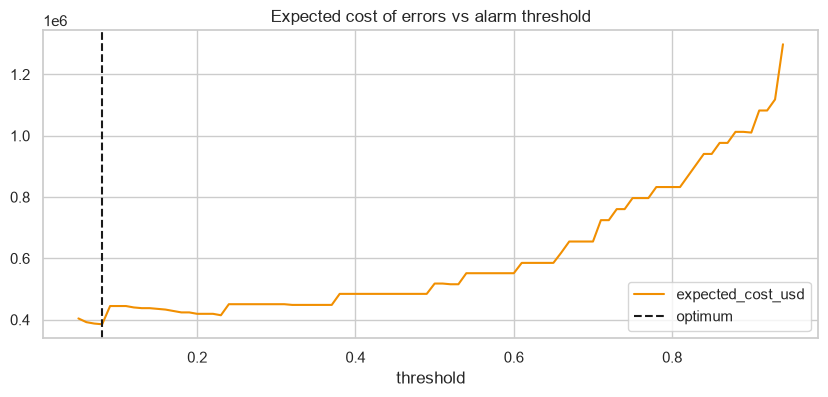

In [5]:
p = pd.read_csv(config.PREDICTIONS_CSV)
thr, table = tune_threshold(p.y_true, p.failure_probability, mode='cost')
print('cost-optimal threshold:', thr)
ax = table[(table.threshold < .95)].plot(x='threshold', y='expected_cost_usd', figsize=(10,4),
        title='Expected cost of errors vs alarm threshold', color='#F18F01')
ax.axvline(thr, ls='--', color='k', label='optimum'); ax.legend()

## 3.4 Business impact of the tuned model

In [6]:
json.dumps(business_impact(m, 30), indent=2)

'{\n  "cost_of_one_unplanned_breakdown_usd": 36000.0,\n  "baseline_run_to_failure_cost_usd": 2448000.0,\n  "cost_with_ai_usd": 437280.0,\n  "net_saving_usd": 2010720.0,\n  "saving_pct": 82.14,\n  "failures_prevented": 57,\n  "failures_missed": 11,\n  "false_alarms": 8,\n  "cost_per_false_alarm_usd": 2310.0,\n  "cost_per_missed_failure_usd": 36000.0,\n  "lives_of_equipment_protected": 68,\n  "sensor_kit_cost_usd": 7500.0,\n  "payback_ratio": 268.1\n}'

## 3.5 EARLY WARNING: how much notice do we actually get?
This is the project's headline result - measured on machines the model never saw.

In [7]:
preds = pd.read_csv(config.STREAM_PRED_CSV)
lead = pd.read_csv(config.OUTPUTS_DIR / 'alert_lead_time_report.csv')
print('breakdowns caught in advance: %.0f%%' % (100 * lead.predicted_in_advance.mean()))
print('average lead time: %.1f cycles (%.1f h)' % (
    lead.lead_time_cycles.mean(), lead.lead_time_hours.mean()))
lead.head(10)

breakdowns caught in advance: 100%
average lead time: 5.3 cycles (0.9 h)


,machine_id,breakdown_cycle,alerts_before_breakdown,first_alert_cycle,lead_time_cycles,predicted_in_advance,lead_time_hours
0,MOTOR-010,140,3,135,5,True,0.83
1,MOTOR-010,283,3,278,5,True,0.83
2,MOTOR-010,426,2,421,5,True,0.83
3,MOTOR-010,568,3,563,5,True,0.83
4,MOTOR-010,709,2,705,4,True,0.67
5,MOTOR-010,852,3,847,5,True,0.83
6,MOTOR-011,149,2,144,5,True,0.83
7,MOTOR-011,298,2,294,4,True,0.67
8,MOTOR-011,448,2,443,5,True,0.83
9,MOTOR-011,597,2,592,5,True,0.83


Text(0.5, 0, 'cycles of advance notice (x 10 min)')

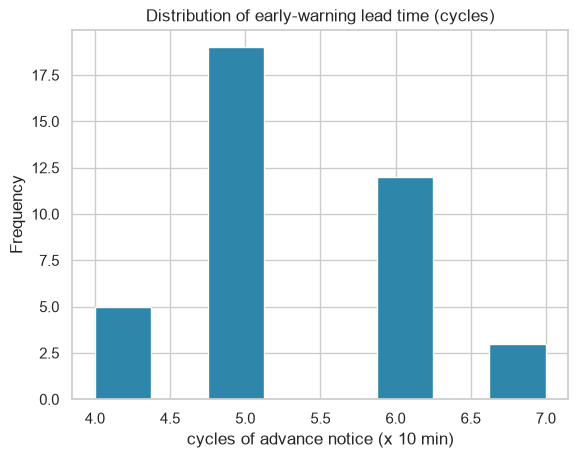

In [8]:
lead.lead_time_cycles.dropna().plot(kind='hist', bins=8, color='#2E86AB',
        title='Distribution of early-warning lead time (cycles)', edgecolor='white')
plt.xlabel('cycles of advance notice (x 10 min)')

## 3.6 What would you do differently with real plant data?
1. Re-train on the plant's own work-order history (labels come from maintenance logs, not from a file).
2. Add remaining-useful-life (RUL) regression on top of classification.
3. Monitor data drift - sensor recalibration changes feature distributions.
4. Model the cost of each machine separately (a bottleneck press is not a fan).

Next: open `outputs/dashboard.html` for the operator console.